<a href="https://colab.research.google.com/github/aakriti1318/llm-inference-sandbox/blob/main/langgraph_101/langgraph_101.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Langgraph

Langgraph - Focuses on agent orchestration, building workflows and modelling whole processes as graphs

LangChain - It's a toolkit for building LLM applications and LLM wrappers.

In [ ]:
!uv init

Initialized project `content`


In [ ]:
!uv add langgraph langchain
# !uv add langchain_nvidia_ai_endpoints

#### Hello world Explanation of Langgraph

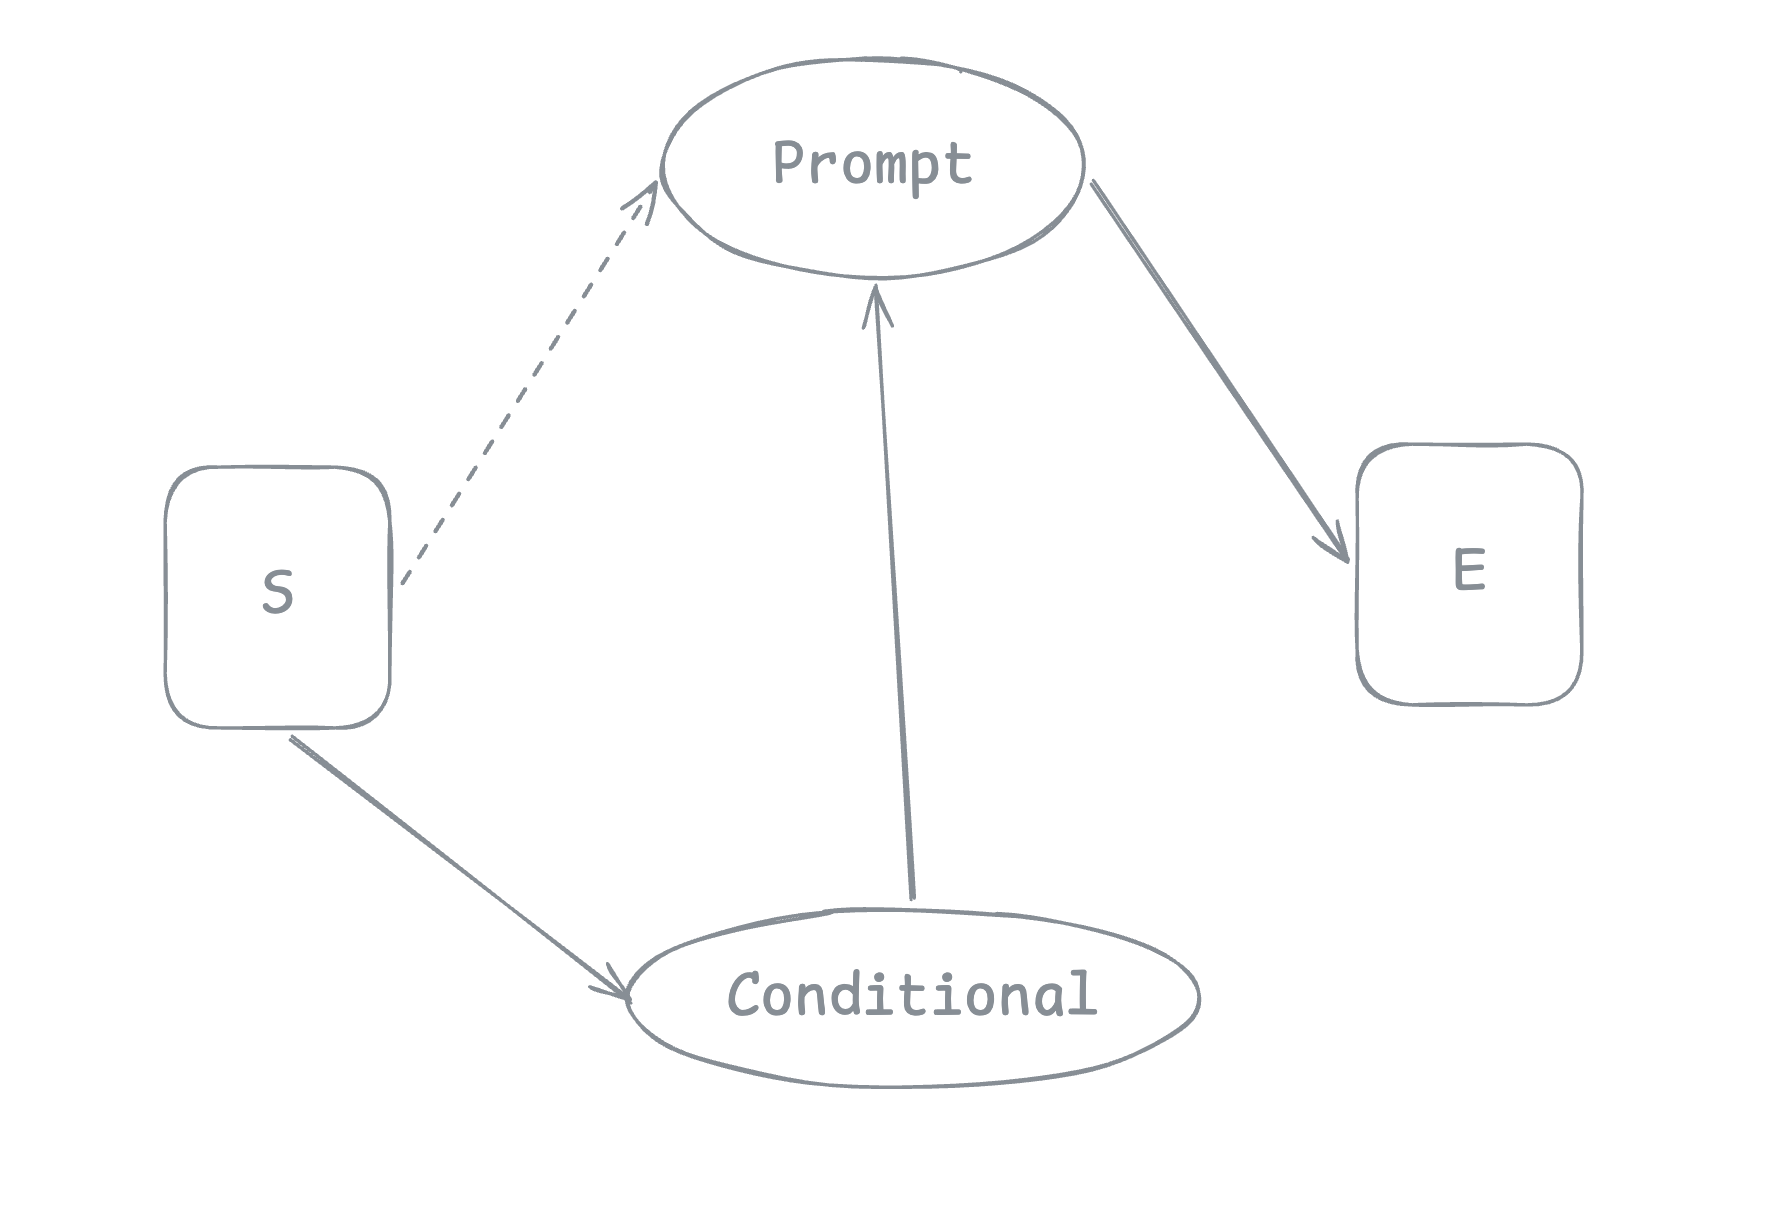

In [ ]:
%pip install -U langchain-nvidia-ai-endpoints

In [ ]:
from langchain.chat_models import init_chat_model
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_nvidia_ai_endpoints import ChatNVIDIA

print("Successfully imported!")

Successfully imported!


In [ ]:
import os
from google.colab import userdata
nvidia_key = userdata.get('NVIDIA_NIM_KEY')

os.environ["NVIDIA_NIM_KEY"] = nvidia_key

print("✅ Key loaded successfully into environment variables!")


✅ Key loaded successfully into environment variables!


In [ ]:
llm = ChatNVIDIA(model="openai/gpt-oss-20b", api_key=nvidia_key)

In [ ]:
def prompt_llm(state: MessagesState): # MessagesState - Append messages not replaced
  response = llm.invoke(state['messages'])
  return {'messages': [response]}

In [ ]:
graph_builder = StateGraph(MessagesState)

graph_builder.add_node(prompt_llm)

graph_builder.add_edge(START, "prompt_llm")

graph_builder.add_edge("prompt_llm", END)

graph = graph_builder.compile()

In [ ]:
user_message = input("Enter Message: ")
print(graph.invoke({'messages': [{'role': 'user', 'content' : user_message}]}))

In [ ]:
# For continuous messages
while True:
  user_message = input("Enter Message: ")
  print(graph.invoke({'messages': [{'role': 'user', 'content' : user_message}]}))

### Adding Memory

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
import uuid

In [ ]:
checkpointer = InMemorySaver()
graph = graph_builder.compile(checkpointer=checkpointer)

config = {'configurable': {'thread_id': uuid.uuid4()}}

while True:
  user_message = input("Enter Message: ")
  print(graph.invoke({'messages': [{'role': 'user', 'content' : user_message}]}, config = config))

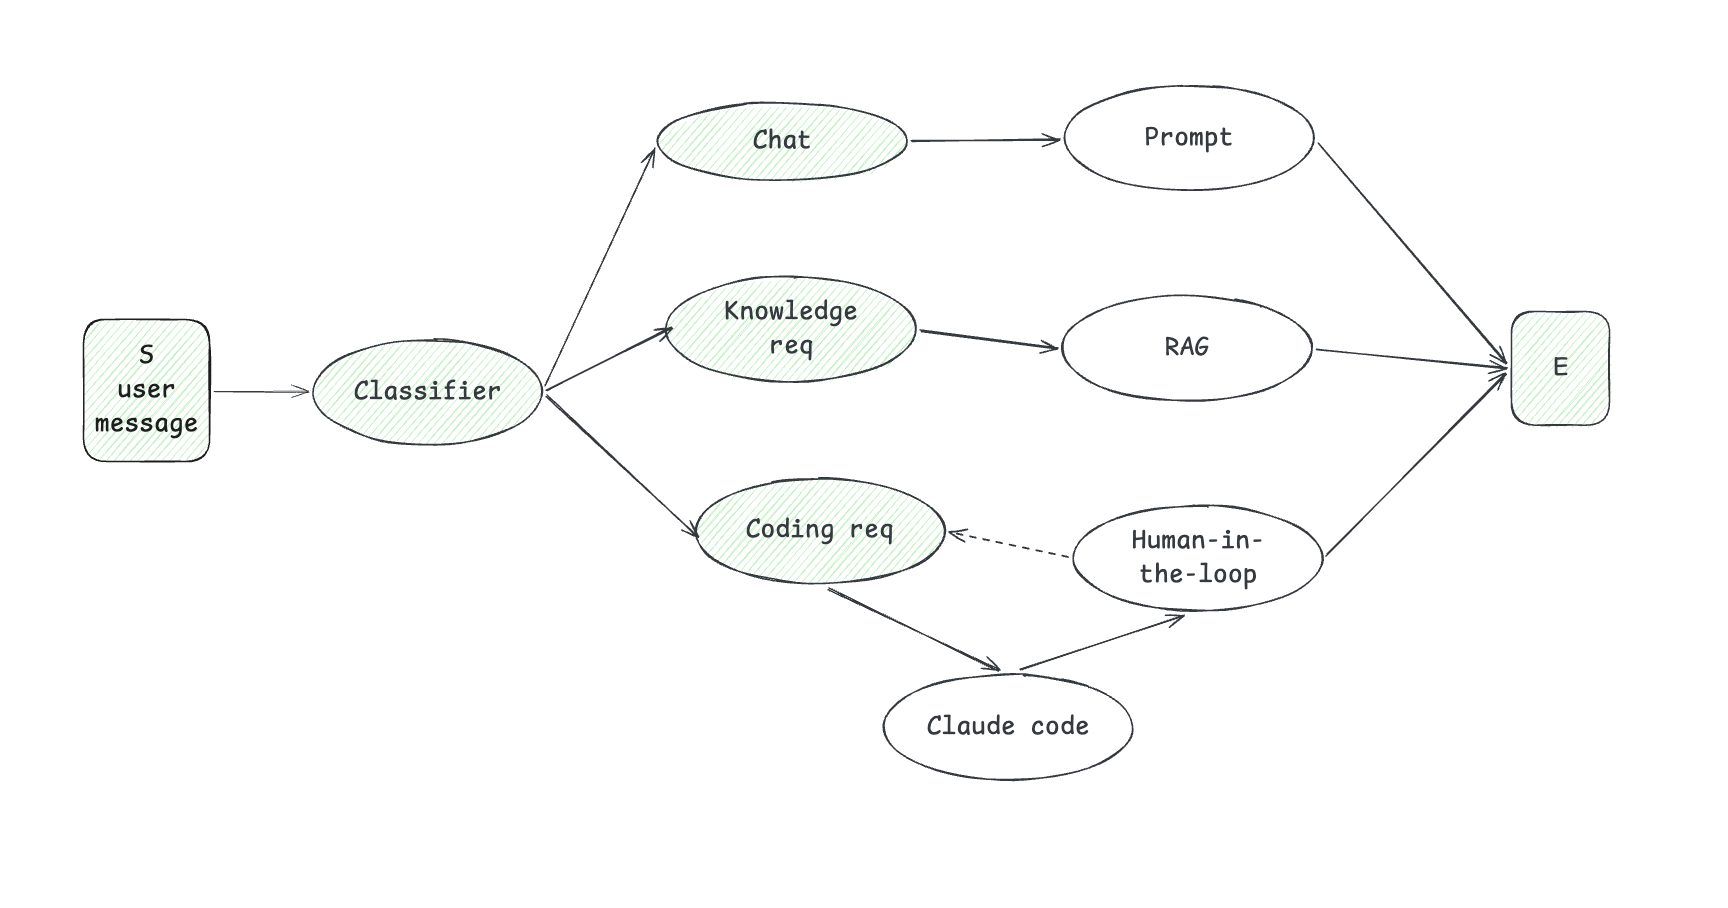

In [ ]:
!uv add pydantic

Resolved 37 packages in 21ms
Prepared 1 package in 4ms
Uninstalled 1 package in 0.41ms
Installed 1 package in 2ms
 ~ content==0.1.0 (from file:///content)


In [ ]:
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from langgraph.graph.message import add_messages

In [ ]:
import uuid
from typing import Literal, Annotated
from pydantic import BaseModel, Field
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver

class IntentClassifier(BaseModel):
    message_intent: Literal['chat', 'knowledge', 'code'] = Field(
        ...,
        description='Classify the message whether the user wants just to chat, ask for knowledge, or change code.'
    )

class State(TypedDict):
    messages: Annotated[list, add_messages]
    message_intent: str | None

def classify_intent(state: State):
    structured_llm = llm.with_structured_output(IntentClassifier)
    result = structured_llm.invoke([
        {'role': 'system',
         'content': 'Determine or classify whether the user wants to: chat "chat", retrieve knowledge "knowledge", change code "code"'},
        {'role': 'user', 'content': state['messages'][-1].content}
    ])
    return {'message_intent': result.message_intent}

def prompt_llm_chat(state: State):
    messages = [{'role': 'system', 'content': 'You are a talkative chatbot for fun. Be nice.'}] + state['messages']
    response = llm.invoke(messages)
    return {'messages': [{'role': 'assistant', 'content': response.content}]}

def prompt_llm_rag(state: State):
    messages = [{'role': 'system', 'content': 'No matter what the user is asking, just reply with "I am the RAG Agent".'}] + state['messages']
    response = llm.invoke(messages)
    return {'messages': [{'role': 'assistant', 'content': response.content}]}

def prompt_llm_code(state: State):
    messages = [{'role': 'system', 'content': 'No matter what the user is asking, just reply with "I am the code Agent".'}] + state['messages']
    response = llm.invoke(messages)
    return {'messages': [{'role': 'assistant', 'content': response.content}]}

# Build the graph
graph_builder = StateGraph(State)
graph_builder.add_node('classifier', classify_intent)
graph_builder.add_node('chat_agent', prompt_llm_chat)
graph_builder.add_node('rag_agent', prompt_llm_rag)
graph_builder.add_node('code_agent', prompt_llm_code)

graph_builder.add_edge(START, 'classifier')

graph_builder.add_conditional_edges(
    'classifier',
    lambda state: state['message_intent'],
    {'chat': 'chat_agent', 'knowledge': 'rag_agent', 'code': 'code_agent'}
)

graph_builder.add_edge('chat_agent', END)
graph_builder.add_edge('rag_agent', END)
graph_builder.add_edge('code_agent', END)

checkpointer = InMemorySaver()
graph = graph_builder.compile(checkpointer=checkpointer)

# Chat Loop Execution
config = {'configurable': {'thread_id': str(uuid.uuid4())}}
while True:
    user_message = input('Enter Message: ')
    if user_message.lower() in ['exit', 'quit']:
        break

    result = graph.invoke({'messages': [{'role': 'user', 'content': user_message}]}, config)
    print(result['messages'][-1].content)
